# Images made of one drop plus a stray pixel

**A single stray pixel beside a small drop makes the drop size as the distance between them, so a 0.2 mm drop reads as 0.5–1.0 mm.** Because Z goes as D⁶, stray pixels on just 0.1 % of images raise Z by 6 dB and on 1 % by 15 dB, while the particle count barely moves. The check needs only the images and the size reported for each: split each large image into pieces and compare the largest piece with the reported size. In the synthetic leg below, the package's correction cuts the images above 400 µm from 45 to 14 and the burst seconds' Z by 25 dB.

**What you get**

- the size inflation, and its effect on N above 400 µm and on Z, as a function of stray-pixel fraction;
- a per-second check that finds the few seconds and images carrying a Z excess;
- the package's correction (`arrayprobe_uiops.stray_pixel.remove_stray_pixels`), which leaves two-drop and scattered-pixel frames untouched.

> **Every number in this notebook is synthetic**: 2D-S-like images (10 µm pixels, 128 diodes) from a fixed random seed; no real data is read.

Sections: 1. the image types; 2. size inflation, N above 400 µm and Z; 3. checking your own data; 4. the correction, before and after.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [14_stray_pixels](14_stray_pixels.ipynb). **Needs:** `pip install "arrayprobe[extra]"` (matplotlib).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

The tools this notebook uses: the package's piece grouping and its stray-pixel correction, and the pixel size and array width of a 2D-S-like probe.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 10, "legend.fontsize": 10, "axes.titlesize": 11})

from arrayprobe.triage_context import piece_groups
from arrayprobe_uiops.stray_pixel import STRAY_GAP_DIODES, remove_stray_pixels

PIXEL_UM = 10.0      # 2D-S-like pixel size
DIODES = 128         # array width

Four ways to build a synthetic image: a single round drop, the same drop with one stray pixel added, two real drops in one frame, and a frame of scattered pixels with no drop.

In [3]:
def drop(diam_px, height=DIODES, width=None, row=None, col=None):
    """A filled disk of diameter ``diam_px`` pixels on an empty frame."""
    width = width or max(int(diam_px) + 8, 16)
    img = np.zeros((height, width), dtype=np.uint8)
    r0 = row if row is not None else height // 2
    c0 = col if col is not None else width // 2
    rr, cc = np.ogrid[:height, :width]
    img[(rr - r0) ** 2 + (cc - c0) ** 2 <= (diam_px / 2) ** 2] = 1
    return img


def add_stray(img, dist_px, angle_deg=30.0):
    """The same frame with one stray pixel ``dist_px`` pixels from the drop's centre."""
    h = img.shape[0]
    rows, cols = np.nonzero(img)
    r0, c0 = rows.mean(), cols.mean()
    r = int(np.clip(round(r0 + dist_px * np.sin(np.radians(angle_deg))), 0, h - 1))
    c = int(round(c0 + dist_px * np.cos(np.radians(angle_deg))))
    out = np.pad(img, ((0, 0), (0, max(0, c - img.shape[1] + 4))))
    out[r, c] = 1
    return out


def two_drops(d1, d2, sep_px):
    w = int(d1 / 2 + sep_px + d2 / 2) + 12
    a = drop(d1, width=w, col=int(d1 / 2) + 4)
    b = drop(d2, width=w, col=int(d1 / 2) + 4 + sep_px)
    return np.maximum(a, b)


def scattered(n_px, rng, width=60):
    img = np.zeros((DIODES, width), dtype=np.uint8)
    img[rng.integers(0, DIODES, n_px), rng.integers(0, width, n_px)] = 1
    return img

Two sizes for each image: the size the processing would report (the widest distance across all its shadowed pixels) and the size of its largest piece. `dbz` converts reflectivity Z to dBZ.

In [4]:
def extent_um(img):
    """Largest distance across the shadowed pixels plus one pixel: a stand-in for the
    enclosing-circle diameter the processing reports (the same for a drop plus one far pixel)."""
    rows, cols = np.nonzero(img)
    if rows.size == 0:
        return 0.0
    pts = np.column_stack([rows, cols]).astype(float)
    if len(pts) > 400:   # the farthest pair always includes an extreme point
        keys = [pts[:, 0], pts[:, 1], pts.sum(1), pts[:, 0] - pts[:, 1]]
        idx = np.unique([f(k) for k in keys for f in (np.argmin, np.argmax)])
        ref = pts[idx]
    else:
        ref = pts
    d = np.sqrt(((pts[:, None, :] - ref[None, :, :]) ** 2).sum(-1)).max()
    return (d + 1.0) * PIXEL_UM


def largest_piece_um(img, gap=STRAY_GAP_DIODES):
    groups = piece_groups(img, gap=gap)
    if not groups:
        return 0.0
    return extent_um(max(groups, key=lambda g: g.sum()))


def dbz(z_linear):
    return 10 * np.log10(z_linear)


print(f"pieces fewer than {STRAY_GAP_DIODES} empty diodes apart are grouped as one particle")

pieces fewer than 8 empty diodes apart are grouped as one particle


A plotting helper: crops each image to its particle, pads every crop to the same size so all panels share one pixel scale, and lays them out in a grid.

In [5]:
def show_grid(images, titles, ncols=3, panel=3.4, crop=True, suptitle=None):
    """Particle images in a grid of large panels (never one long row)."""
    nrows = int(np.ceil(len(images) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel * ncols, panel * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    crops = []
    for img in images:
        rows, cols = np.nonzero(img)
        if crop and rows.size:
            img = img[max(rows.min() - 3, 0):rows.max() + 4, max(cols.min() - 3, 0):cols.max() + 4]
        crops.append(img)
    # every panel on one pixel scale: pad each crop to the largest crop's size
    hmax = max(c.shape[0] for c in crops)
    wmax = max(c.shape[1] for c in crops)
    crops = [np.pad(c, (((hmax - c.shape[0]) // 2, hmax - c.shape[0] - (hmax - c.shape[0]) // 2),
                        ((wmax - c.shape[1]) // 2, wmax - c.shape[1] - (wmax - c.shape[1]) // 2)))
             for c in crops]
    for ax, img, t in zip(axes.ravel(), crops, titles):
        ax.imshow(img, cmap="Greys", interpolation="nearest", vmin=0, vmax=1)
        ax.set_title(t, fontsize=10)
        ax.axis("on")
        ax.set_xticks([])
        ax.set_yticks([])
    if suptitle:
        fig.suptitle(suptitle, fontsize=12)
    fig.tight_layout()
    return fig

## 1. The image types

Six frames: a clean 200 µm drop; the same drop with one stray pixel 30, 50 and 80 pixels from its centre; two real drops in one frame; and a frame of scattered pixels with no drop in it. Each panel's title gives the reported size (the enclosing extent) and the size of the largest piece.

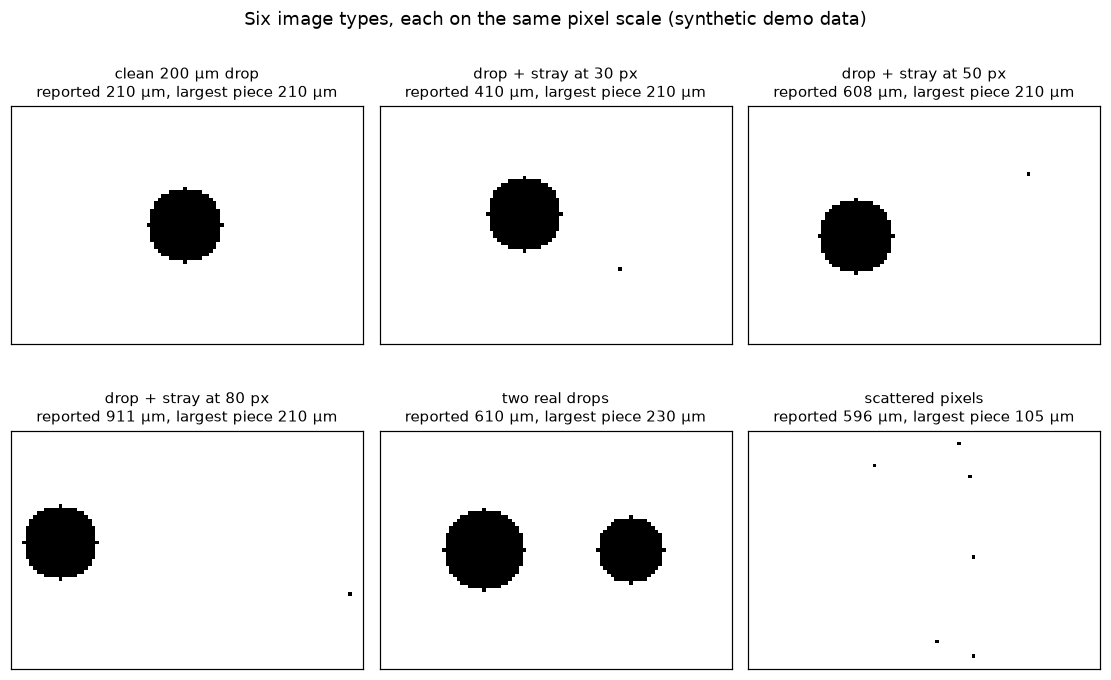

In [6]:
rng = np.random.default_rng(24)
clean = drop(20)
examples = {
    "clean 200 µm drop": clean,
    "drop + stray at 30 px": add_stray(clean, 30),
    "drop + stray at 50 px": add_stray(clean, 50, angle_deg=-20),
    "drop + stray at 80 px": add_stray(clean, 80, angle_deg=10),
    "two real drops": two_drops(22, 18, 40),
    "scattered pixels": scattered(6, rng),
}
titles = [f"{k}\nreported {extent_um(v):.0f} µm, largest piece {largest_piece_um(v):.0f} µm"
          for k, v in examples.items()]
show_grid(list(examples.values()), titles, ncols=3,
          suptitle="Six image types, each on the same pixel scale (synthetic demo data)")
plt.show()

*Figure 1. Six synthetic image types, cropped and shown on one pixel scale, each titled with the size the processing would report and the size of its largest piece.*

## 2. How much the size inflates, and what that does to N above 400 µm and to Z

The reported size of a drop plus one stray pixel grows with the distance to the stray pixel, whatever the drop's size. The second part takes a toy drop population (mode near 0.1 mm, almost nothing above 0.4 mm) and gives a small fraction of its images one stray pixel, reporting them at 0.3–1.0 mm. The particle count is unchanged; the count above 400 µm and Z are not.

stray fraction  0.0 %: N > 400 µm =   23, Z =  19.99 dBZ, difference from clean =  +0.00 dB
stray fraction  0.1 %: N > 400 µm =   43, Z =  26.03 dBZ, difference from clean =  +6.04 dB
stray fraction  0.3 %: N > 400 µm =   88, Z =  31.41 dBZ, difference from clean = +11.43 dB
stray fraction  1.0 %: N > 400 µm =  174, Z =  35.01 dBZ, difference from clean = +15.02 dB
stray fraction  3.0 %: N > 400 µm =  533, Z =  39.87 dBZ, difference from clean = +19.88 dB


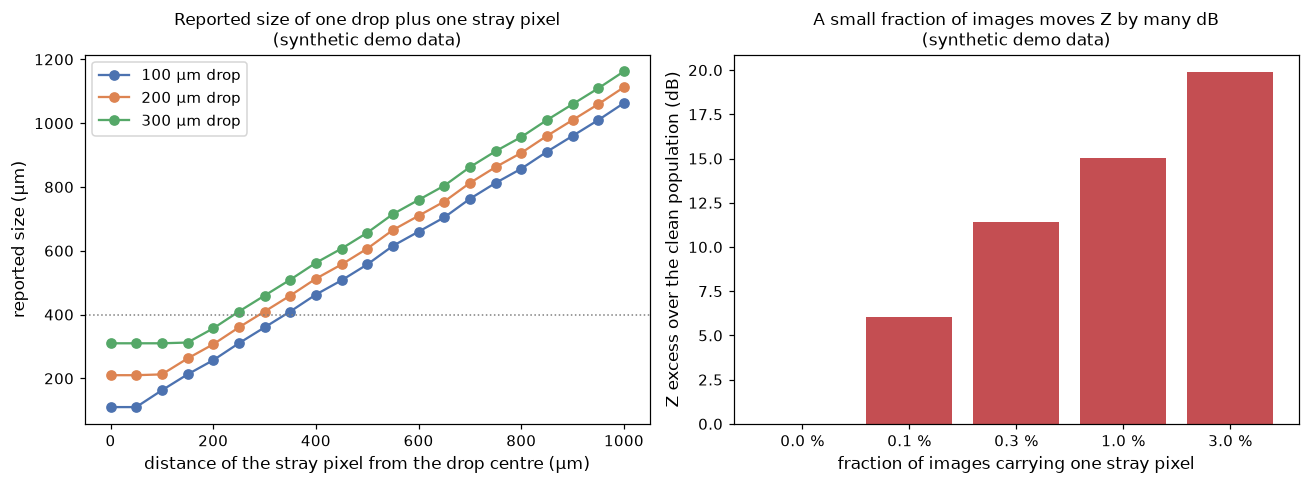

In [7]:
dists = np.arange(0, 101, 5)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for d_px, colour in [(10, "#4c72b0"), (20, "#dd8452"), (30, "#55a868")]:
    base = drop(d_px)
    sizes = [extent_um(base if s == 0 else add_stray(base, s)) for s in dists]
    ax1.plot(dists * PIXEL_UM, sizes, "o-", color=colour, label=f"{d_px * PIXEL_UM:.0f} µm drop")
ax1.axhline(400, color="grey", ls=":", lw=1)
ax1.set_xlabel("distance of the stray pixel from the drop centre (µm)")
ax1.set_ylabel("reported size (µm)")
ax1.set_title("Reported size of one drop plus one stray pixel\n(synthetic demo data)")
ax1.legend()

SAMPLE_VOLUME_M3 = 0.013   # toy value: about one second of a 2D-S-like probe at 170 m/s
rng = np.random.default_rng(7)
true_um = rng.gamma(shape=4.0, scale=30.0, size=20000) + 20
rows = []
for f in [0.0, 0.001, 0.003, 0.01, 0.03]:
    hit = rng.random(true_um.size) < f
    reported = true_um.copy()
    reported[hit] = np.maximum(true_um[hit], rng.uniform(300, 1000, hit.sum()))
    z = ((reported / 1000.0) ** 6).sum() / SAMPLE_VOLUME_M3          # mm^6 m^-3
    rows.append((f, int((reported > 400).sum()), dbz(z)))
z0 = rows[0][2]
for f, n400, zdb in rows:
    print(f"stray fraction {100 * f:4.1f} %: N > 400 µm = {n400:4d}, Z = {zdb:6.2f} dBZ, "
          f"difference from clean = {zdb - z0:+6.2f} dB")
ax2.bar([f"{100 * f:.1f} %" for f, _, _ in rows], [r[2] - z0 for r in rows], color="#c44e52")
ax2.set_xlabel("fraction of images carrying one stray pixel")
ax2.set_ylabel("Z excess over the clean population (dB)")
ax2.set_title("A small fraction of images moves Z by many dB\n(synthetic demo data)")
fig.tight_layout()
plt.show()

*Figure 2. Left: reported size of a 100, 200 and 300 µm drop as one stray pixel moves away from it; the dotted line marks 400 µm. Right: the excess in Z when a given fraction of images carries one stray pixel.*

## 3. Checking your own data

The check needs only the particle images and the size the product reports for each. For every image above a size of interest (here 400 µm):

1. split it into pieces with `arrayprobe.triage_context.piece_groups` (8-connected pieces, grouped when at most 8 empty diodes apart);
2. compare the extent of the **largest** piece with the reported size, and flag the image when the largest piece is less than half of it;
3. count the flagged images per second, and compute each second's Z with and without them;
4. look at the images in the seconds that carry most of the Z.

Below, a synthetic 120-second leg stands in for your data: clean drops throughout, an occasional frame with two real drops or with scattered pixels, and an episode in seconds 60–69 in which one image in eight carries a stray pixel (the kind of burst a flickering diode produces). With your own files, replace `leg` with your images and the sizes your product reports for them.

In [8]:
rng = np.random.default_rng(2024)
leg = []   # (second, kind, image)
for sec in range(120):
    stray_rate = 0.125 if 60 <= sec < 70 else 0.002
    for _ in range(rng.poisson(25)):
        d_px = int(np.clip(rng.gamma(4.0, 3.0) + 3, 4, 45))
        img, kind = drop(d_px), "clean"
        if rng.random() < stray_rate:
            img = add_stray(img, int(rng.uniform(30, 90)), angle_deg=rng.uniform(-60, 60))
            kind = "stray"
        leg.append((sec, kind, img))
    if rng.random() < 0.03:
        leg.append((sec, "two drops", two_drops(int(rng.uniform(18, 30)),
                                                 int(rng.uniform(15, 25)),
                                                 int(rng.uniform(35, 55)))))
    if rng.random() < 0.03:
        leg.append((sec, "scattered", scattered(int(rng.integers(4, 9)), rng)))
leg = [(s, k, im, extent_um(im)) for s, k, im in leg]   # the reported size of each image

SIZE_OF_INTEREST_UM = 400.0
FLAG_RATIO = 0.5
flags = []   # (index, second, kind, reported, largest piece, flagged)
for i, (s, k, im, rep) in enumerate(leg):
    if rep > SIZE_OF_INTEREST_UM:
        lp = largest_piece_um(im)
        flags.append((i, s, k, rep, lp, lp < FLAG_RATIO * rep))

n_flag = sum(f[5] for f in flags)
print(f"{len(leg)} images in the leg, {len(flags)} reported above {SIZE_OF_INTEREST_UM:.0f} µm, "
      f"{n_flag} of them flagged (largest piece < {FLAG_RATIO:.0%} of the reported size)")
by_kind = {}
for _, _, k, _, _, fl in flags:
    by_kind.setdefault(k, [0, 0])
    by_kind[k][0] += 1
    by_kind[k][1] += fl
for k, (n, nf) in sorted(by_kind.items()):
    print(f"  {k:10s}: {n:3d} above {SIZE_OF_INTEREST_UM:.0f} µm, {nf:3d} flagged")

3115 images in the leg, 45 reported above 400 µm, 38 of them flagged (largest piece < 50% of the reported size)
  clean     :   5 above 400 µm,   0 flagged
  scattered :   4 above 400 µm,   4 flagged
  stray     :  31 above 400 µm,  29 flagged
  two drops :   5 above 400 µm,   5 flagged


Per second: the number of flagged images, and Z with every image against Z with the flagged images set aside. A second whose Z drops by many dB when its flagged images are set aside is carried by them.

seconds where the flagged images add the most Z:
  second  62: 4 flagged, Z  20.93 dBZ with them, -14.92 dBZ without, difference +35.85 dB
  second  83: 1 flagged, Z  17.26 dBZ with them, -18.52 dBZ without, difference +35.78 dB
  second  63: 4 flagged, Z  19.13 dBZ with them, -13.56 dBZ without, difference +32.69 dB
  second  97: 1 flagged, Z  22.53 dBZ with them,  -6.21 dBZ without, difference +28.74 dB
  second  64: 3 flagged, Z  18.58 dBZ with them,  -6.81 dBZ without, difference +25.38 dB
over the whole leg the 38 flagged images carry 97.1 % of Z (+15.30 dB on the leg mean)


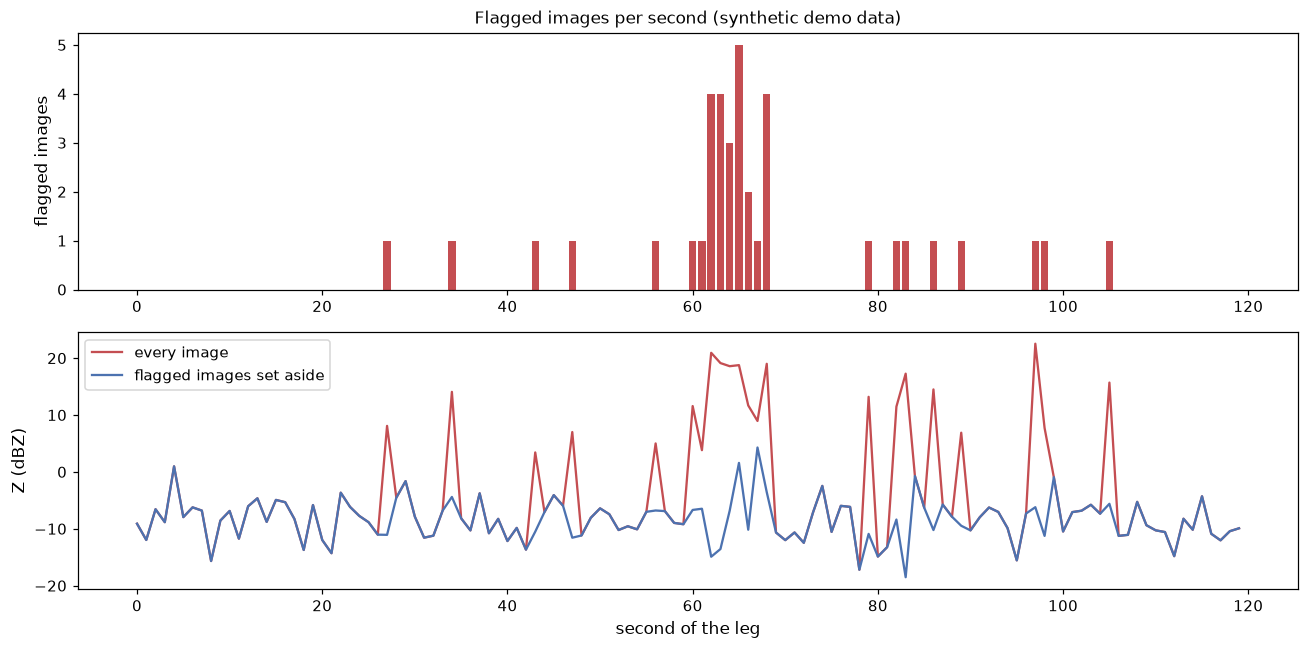

In [9]:
seconds = np.arange(120)
z_all, z_unflagged = np.zeros(120), np.zeros(120)
n_flag_sec = np.zeros(120, int)
flagged_idx = {f[0] for f in flags if f[5]}
for i, (s, k, im, rep) in enumerate(leg):
    z = (rep / 1000.0) ** 6 / SAMPLE_VOLUME_M3
    z_all[s] += z
    if i in flagged_idx:
        n_flag_sec[s] += 1
    else:
        z_unflagged[s] += z

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.bar(seconds, n_flag_sec, color="#c44e52")
ax1.set_ylabel("flagged images")
ax1.tick_params(labelbottom=True)
ax1.set_title("Flagged images per second (synthetic demo data)")
ax2.plot(seconds, dbz(z_all), color="#c44e52", label="every image")
ax2.plot(seconds, dbz(z_unflagged), color="#4c72b0", label="flagged images set aside")
ax2.set_ylabel("Z (dBZ)")
ax2.set_xlabel("second of the leg")
ax2.legend()
fig.tight_layout()
plt.show()

excess_db = dbz(z_all) - dbz(z_unflagged)
top = np.argsort(excess_db)[::-1][:5]
print("seconds where the flagged images add the most Z:")
for s in top:
    print(f"  second {s:3d}: {n_flag_sec[s]} flagged, Z {dbz(z_all[s]):6.2f} dBZ with them, "
          f"{dbz(z_unflagged[s]):6.2f} dBZ without, difference {excess_db[s]:+.2f} dB")
share = 1 - z_unflagged.sum() / z_all.sum()
print(f"over the whole leg the {n_flag} flagged images carry {100 * share:.1f} % of Z "
      f"({dbz(z_all.mean()) - dbz(z_unflagged.mean()):+.2f} dB on the leg mean)")

*Figure 3. Top: flagged images per second of the synthetic leg. Bottom: Z per second with every image, and with the flagged images set aside.*

Now look at the images. The grid shows flagged images from the seconds that carry most of the Z, then a few flagged images of the other kinds, each with its reported size and the size of its largest piece. A compact drop with an isolated pixel or two far away is a stray-pixel image. Two compact pieces of similar size are two real particles in one frame, and a frame of scattered single pixels holds no particle at all; both are flagged too, and need a different answer.

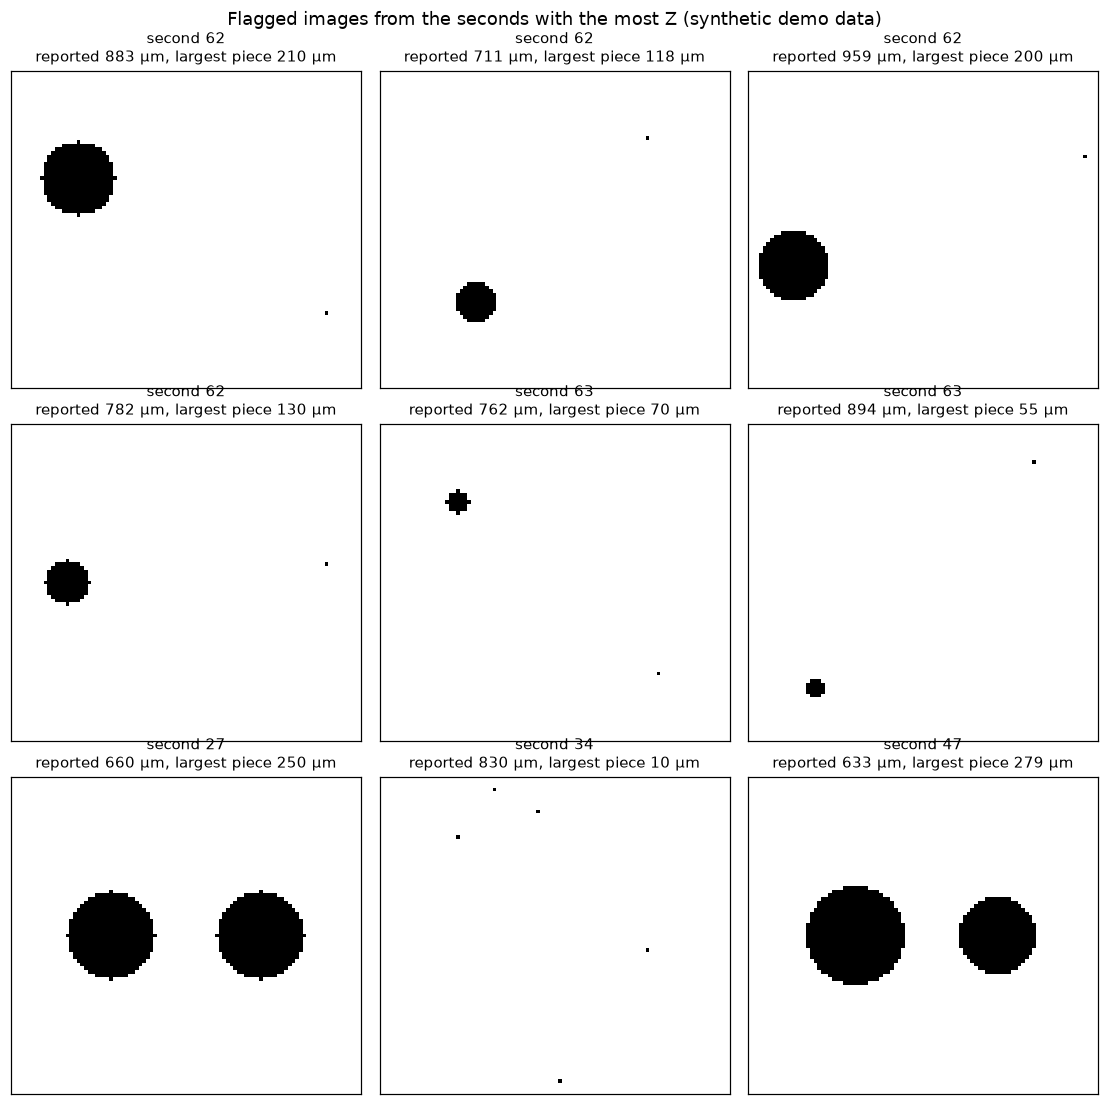

In [10]:
top_set = set(top.tolist())
picked = [f for f in flags if f[5] and f[1] in top_set][:6]
picked += [f for f in flags if f[5] and f[2] != "stray"][:3]
show_grid([leg[f[0]][2] for f in picked],
          [f"second {f[1]}\nreported {f[3]:.0f} µm, largest piece {f[4]:.0f} µm" for f in picked],
          ncols=3, suptitle="Flagged images from the seconds with the most Z (synthetic demo data)")
plt.show()

*Figure 4. Flagged images from the seconds whose Z they inflate most, then flagged images of the other kinds, each titled with its reported size and its largest piece.*

## 4. Applying the correction

`remove_stray_pixels(image)` groups the image's pieces at the same 8-diode gap and removes the small ones only when the image is unambiguous: exactly one piece of at least 9 pixels (a 3 × 3 drop), and every other piece at most 2 pixels. Two real drops and frames of scattered pixels come back unchanged, as the same object. The cleaned image is then sized again, as the processing would size it.

images corrected, by kind: {'stray': 34}
N above 400 µm: 45 before, 14 after
leg-mean Z: 8.63 dBZ before, 4.44 dBZ after, difference +4.19 dB
seconds 60-69: 16.74 dBZ before, -8.22 dBZ after, difference +24.96 dB


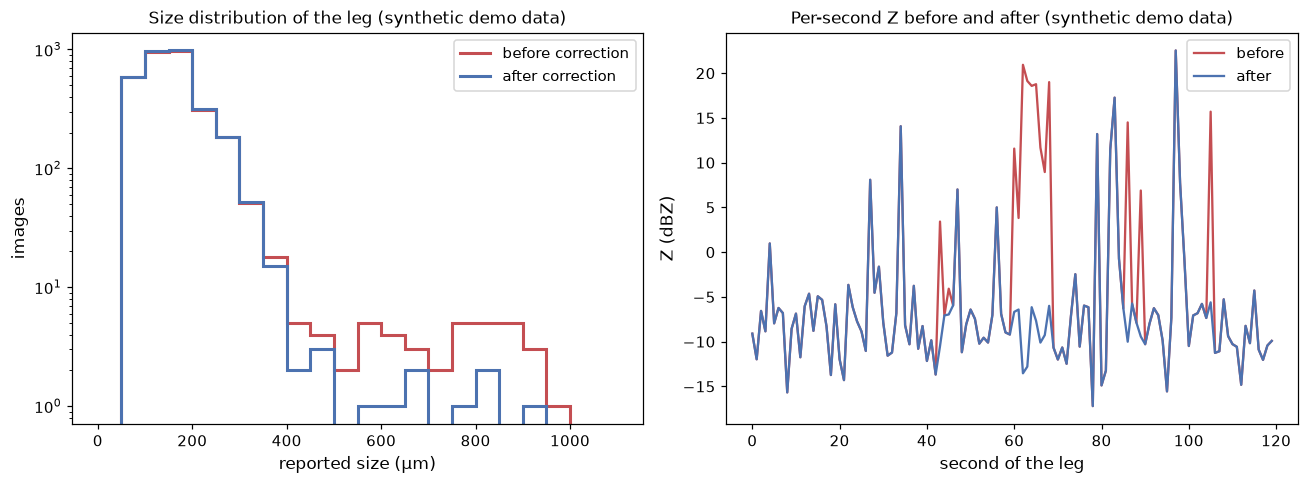

In [11]:
after, n_fixed = [], {}
for s, k, im, rep in leg:
    cleaned, rec = remove_stray_pixels(im)
    if rec["removed"]:
        n_fixed[k] = n_fixed.get(k, 0) + 1
        after.append(extent_um(cleaned))
    else:
        after.append(rep)
after = np.array(after)
before = np.array([r for _, _, _, r in leg])
print("images corrected, by kind:", n_fixed)
print(f"N above {SIZE_OF_INTEREST_UM:.0f} µm: {(before > SIZE_OF_INTEREST_UM).sum()} before, "
      f"{(after > SIZE_OF_INTEREST_UM).sum()} after")

z_before, z_after = np.zeros(120), np.zeros(120)
for (s, k, im, rep), a in zip(leg, after):
    z_before[s] += (rep / 1000.0) ** 6 / SAMPLE_VOLUME_M3
    z_after[s] += (a / 1000.0) ** 6 / SAMPLE_VOLUME_M3
print(f"leg-mean Z: {dbz(z_before.mean()):.2f} dBZ before, {dbz(z_after.mean()):.2f} dBZ after, "
      f"difference {dbz(z_before.mean()) - dbz(z_after.mean()):+.2f} dB")
print(f"seconds 60-69: {dbz(z_before[60:70].mean()):.2f} dBZ before, "
      f"{dbz(z_after[60:70].mean()):.2f} dBZ after, "
      f"difference {dbz(z_before[60:70].mean()) - dbz(z_after[60:70].mean()):+.2f} dB")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.arange(0, 1101, 50)
ax1.hist(before, bins=bins, histtype="step", lw=2, color="#c44e52", label="before correction")
ax1.hist(after, bins=bins, histtype="step", lw=2, color="#4c72b0", label="after correction")
ax1.set_yscale("log")
ax1.set_xlabel("reported size (µm)")
ax1.set_ylabel("images")
ax1.set_title("Size distribution of the leg (synthetic demo data)")
from matplotlib.lines import Line2D
ax1.legend(handles=[Line2D([], [], color="#c44e52", lw=2, label="before correction"),
                    Line2D([], [], color="#4c72b0", lw=2, label="after correction")])
ax2.plot(seconds, dbz(z_before), color="#c44e52", label="before")
ax2.plot(seconds, dbz(z_after), color="#4c72b0", label="after")
ax2.set_xlabel("second of the leg")
ax2.set_ylabel("Z (dBZ)")
ax2.set_title("Per-second Z before and after (synthetic demo data)")
ax2.legend()
fig.tight_layout()
plt.show()

*Figure 5. Left: size distribution of the leg before and after the stray-pixel correction. Right: per-second Z before and after.*

Three stray-pixel images before and after the correction, one pair per row.

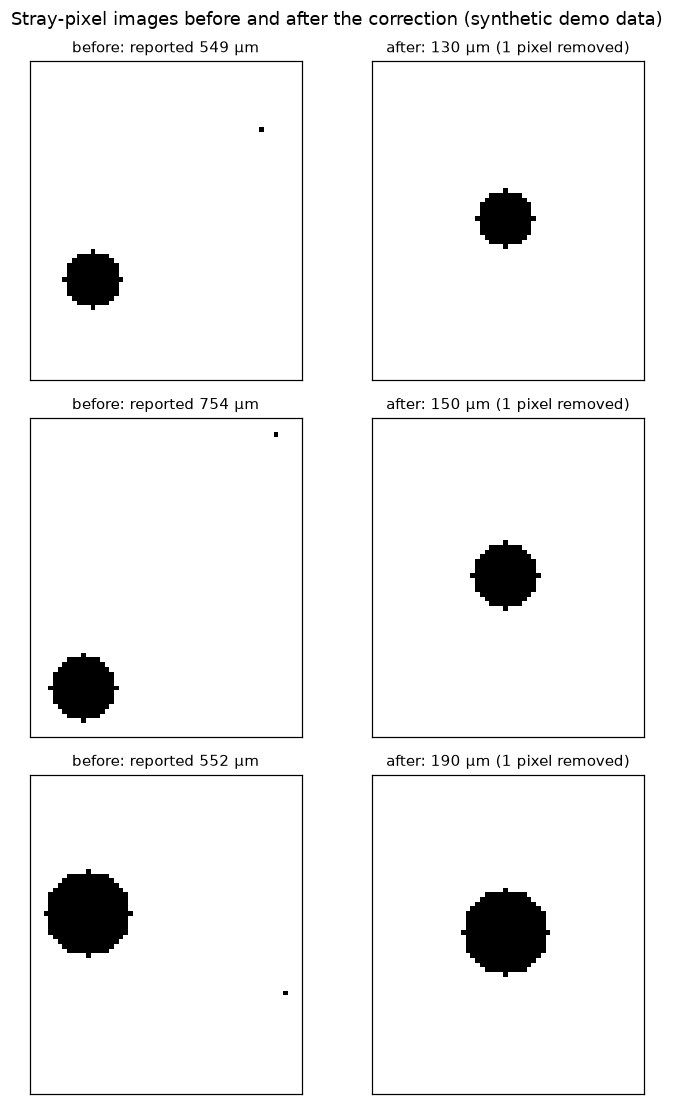

In [12]:
pairs = [i for i, (s, k, im, rep) in enumerate(leg) if k == "stray" and rep > 500][:3]
imgs, ttl = [], []
for i in pairs:
    im = leg[i][2]
    cleaned, rec = remove_stray_pixels(im)
    imgs += [im, cleaned]
    ttl += [f"before: reported {extent_um(im):.0f} µm",
            f"after: {extent_um(cleaned):.0f} µm ({rec['removed']} pixel removed)"]
show_grid(imgs, ttl, ncols=2,
          suptitle="Stray-pixel images before and after the correction (synthetic demo data)")
plt.show()

*Figure 6. Three stray-pixel images (left) and the same images after the correction (right).*

## What to take away

- A stray pixel inflates the reported size by its distance from the drop, not by anything about the drop, so the error is largest for small drops with a far-off stray.
- The particle count hardly changes, but N above 400 µm and Z can change by many dB, carried by a few images in a few seconds. A Z difference between two processings concentrated in a handful of seconds is worth this check before any other explanation.
- The check is cheap: split every large image into pieces, compare the largest piece with the reported size, and look at the flagged images in the seconds that carry Z.
- The correction removes strays only when one piece is clearly the particle; two real drops and frames of scattered pixels are left for other checks. Its thresholds (a gap of 8 diodes, strays of at most 2 pixels, a main piece of at least 9) are the module's defaults and are arguments you can change.